#### ESCUELA POLIECTNICA NACIONAL 
#### MTODOS NUMRICOS 
#### DANNY CAIZA 

## DEBER - Interpolacion Y Poinomios de Taylor
22 de Noviembre de 2026
_________________________

2.1(a) Secante (0, 1): -0.040659
2.1(b) Newton (0.5):   -0.040659
2.2 Cero en [0, 1]:    0.962398


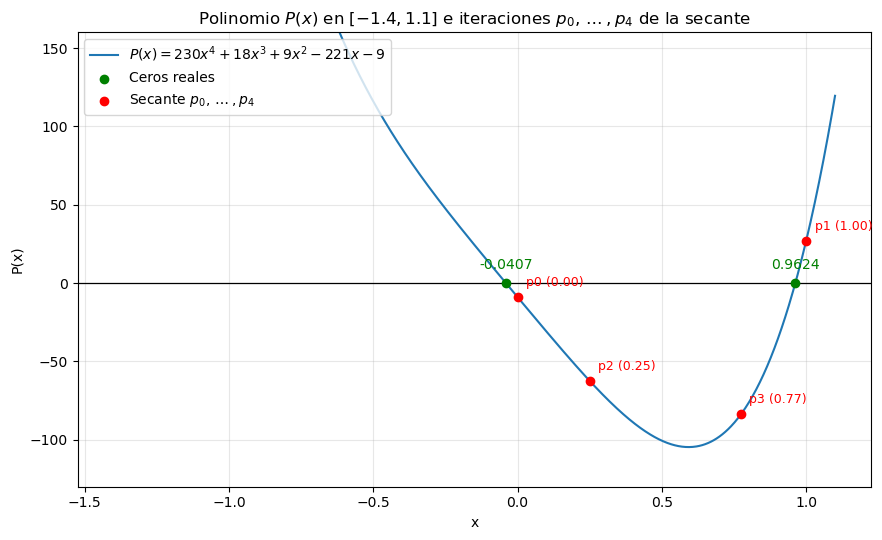

2.6 25.º cero positivo: 24.499887


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def P(x):
    return 230*x**4 + 18*x**3 + 9*x**2 - 221*x - 9

def dP(x):
    return 920*x**3 + 54*x**2 + 18*x - 221

def secante(func, p0, p1, tol=1e-6, max_iter=100):
    hist = [p0, p1]
    for _ in range(max_iter):
        f0, f1 = func(hist[-2]), func(hist[-1])
        if abs(f1 - f0) == 0:
            break
        p_next = hist[-1] - f1 * (hist[-1] - hist[-2]) / (f1 - f0)
        hist.append(p_next)
        if abs(p_next - hist[-2]) < tol:
            break
    return hist[-1], hist

def newton(func, dfunc, p0, tol=1e-6, max_iter=100):
    hist = [p0]
    for _ in range(max_iter):
        p_prev = hist[-1]
        df_val = dfunc(p_prev)
        if df_val == 0:
            break
        p_next = p_prev - func(p_prev) / df_val
        hist.append(p_next)
        if abs(p_next - p_prev) < tol:
            break
    return hist[-1], hist

def biseccion(func, a, b, tol=1e-12, max_iter=200):
    fa, fb = func(a), func(b)
    for _ in range(max_iter):
        m = 0.5 * (a + b)
        fm = func(m)
        if abs(b - a) / 2 < tol or fm == 0:
            return m
        if fa * fm < 0:
            b, fb = m, fm
        else:
            a, fa = m, fm
    return 0.5 * (a + b)

# 2.1 y 2.2
r_neg = biseccion(P, -1.0, 0.0)
r_pos = biseccion(P, 0.0, 1.0)
sec_val, _ = secante(P, 0.0, 1.0, tol=1e-6)
new_mid_val, _ = newton(P, dP, 0.5, tol=1e-6)
new_pos_val, _ = newton(P, dP, 0.85, tol=1e-6)

print(f"2.1(a) Secante (0, 1): {sec_val:.6f}")
print(f"2.1(b) Newton (0.5):   {new_mid_val:.6f}")
print(f"2.2 Cero en [0, 1]:    {new_pos_val:.6f}")

# 2.4 Gráfica de P en [-1.4, 1.1] con p0..p4
_, hist_sec = secante(P, 0.0, 1.0, tol=1e-15, max_iter=4)
p0_4 = hist_sec[:5]

xs = np.linspace(-1.4, 1.1, 1000)
plt.figure(figsize=(9, 5.5))
plt.plot(xs, P(xs), label=r"$P(x) = 230x^4 + 18x^3 + 9x^2 - 221x - 9$")
plt.axhline(0, color="black", linewidth=0.9)
plt.ylim(-130, 160)

# Marcar los dos ceros reales
ceros = [r_neg, r_pos]
plt.scatter(ceros, [0, 0], color="green", zorder=5, label="Ceros reales")
for c in ceros:
    plt.annotate(f"{c:.4f}", (c, 0), textcoords="offset points", xytext=(0, 10), ha="center", color="green")

# Marcar y numerar p0..p4
plt.scatter(p0_4, P(np.array(p0_4)), color="red", marker="o", zorder=6, label=r"Secante $p_0,\dots,p_4$")
for idx, pk in enumerate(p0_4):
    plt.annotate(f"p{idx} ({pk:.2f})", (pk, P(pk)), textcoords="offset points", xytext=(6, 8), color="red", fontsize=9)

plt.title(r"Polinomio $P(x)$ en $[-1.4, 1.1]$ e iteraciones $p_0, \dots, p_4$ de la secante")
plt.xlabel("x")
plt.ylabel("P(x)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("seccion2_polinomio.png", dpi=150)
plt.show()

# 2.5 y 2.6: f(x) = ln(x^2 + 1) - exp(0.4*x)*cos(pi*x)
def f_osc(x):
    return np.log(x**2 + 1.0) - np.exp(0.4*x) * np.cos(np.pi * x)

n25 = 25
aprox25 = n25 - 0.5
r25, _ = secante(f_osc, aprox25 - 0.05, aprox25 + 0.05, tol=1e-6)
print(f"2.6 25.º cero positivo: {r25:.6f}")

## 3. Cuando no hay raíz

Hasta ahora, cuando Newton o la secante fallaban, había una raíz. En esta sección no la hay, pero $\vert{}f\vert{}$ se acerca a cero. Use su `newton_raphson` con $TOL = 10^{-6}$ y $N_0 = 50$.

La función $f(x) = e^x$ no tiene ceros: $e^x > 0$ para todo $x$, y $e^x \to 0$ cuando $x \to -\infty$.

3.2 Error esperado: Se alcanzó N0 sin cumplir la tolerancia del paso.
3.3 Con criterio de residuo: p = -14.000000 en 14 iteraciones


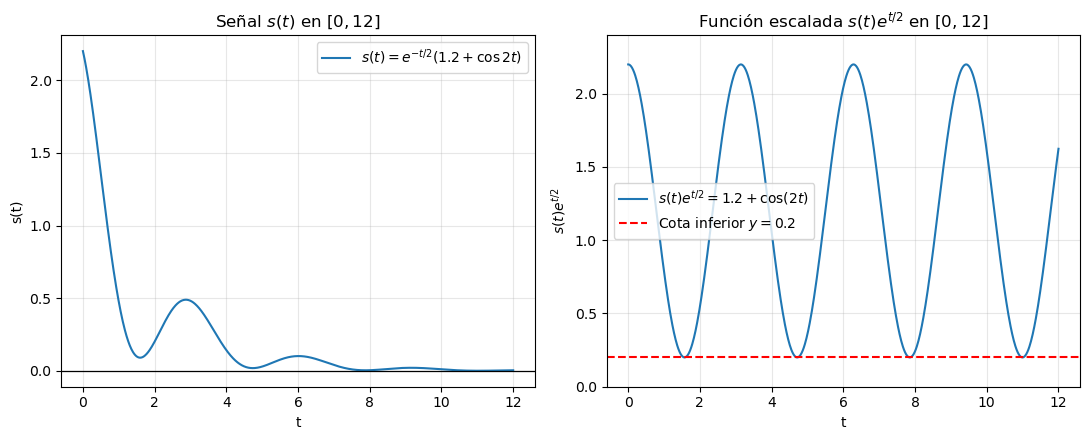

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

def newton_raphson(f, df, p0, tol=1e-6, n0=50, por_residuo=False):
    p = p0
    for n in range(1, n0 + 1):
        dfp = df(p)
        if dfp == 0:
            raise ZeroDivisionError("Derivada nula en Newton.")
        p_next = p - f(p) / dfp
        if por_residuo:
            if abs(f(p_next)) < tol:
                return p_next, n
        else:
            if abs(p_next - p) < tol:
                return p_next, n
        p = p_next
    if por_residuo:
        return p, n0
    raise RuntimeError("Se alcanzó N0 sin cumplir la tolerancia del paso.")

try:
    newton_raphson(np.exp, np.exp, 0.0, tol=1e-6, n0=50, por_residuo=False)
except RuntimeError as e:
    print("3.2 Error esperado:", e)

p_res, it_res = newton_raphson(np.exp, np.exp, 0.0, tol=1e-6, n0=50, por_residuo=True)
print(f"3.3 Con criterio de residuo: p = {p_res:.6f} en {it_res} iteraciones")


t_grid = np.linspace(0.0, 12.0, 800)
s_vals = s_func(t_grid)
scaled_vals = s_vals * np.exp(t_grid / 2.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.plot(t_grid, s_vals, label=r"$s(t) = e^{-t/2}(1.2 + \cos 2t)$")
ax1.axhline(0.0, color="black", linewidth=0.9)
ax1.set_title(r"Señal $s(t)$ en $[0, 12]$")
ax1.set_xlabel("t")
ax1.set_ylabel("s(t)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(t_grid, scaled_vals, label=r"$s(t)e^{t/2} = 1.2 + \cos(2t)$")
ax2.axhline(0.2, color="red", linestyle="--", label=r"Cota inferior $y = 0.2$")
ax2.set_ylim(0.0, 2.4)
ax2.set_title(r"Función escalada $s(t)e^{t/2}$ en $[0, 12]$")
ax2.set_xlabel("t")
ax2.set_ylabel(r"$s(t)e^{t/2}$")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("seccion3_senal.png", dpi=150)
plt.show()

In [3]:
def s_func(t):
    return np.exp(-t / 2.0) * (1.2 + np.cos(2.0 * t))

def ds_func(t):
    return -0.5 * np.exp(-t / 2.0) * (1.2 + np.cos(2.0 * t)) - 2.0 * np.exp(-t / 2.0) * np.sin(2.0 * t)

for t0 in [0.0, 2.0, 3.0, 4.0]:
    t_val, n_val = newton_raphson(s_func, ds_func, t0, tol=1e-6, n0=200, por_residuo=True)
    print(
        f"3.4 t0={t0}: t={t_val:.6f} (n={n_val}), "
        f"s(t-0.01)={s_func(t_val - 0.01):.3e}, s(t+0.01)={s_func(t_val + 0.01):.3e}"
    )

3.4 t0=0.0: t=49.130307 (n=12), s(t-0.01)=1.166e-11, s(t+0.01)=1.220e-11
3.4 t0=2.0: t=49.130307 (n=11), s(t-0.01)=1.166e-11, s(t+0.01)=1.220e-11
3.4 t0=3.0: t=184.224760 (n=10), s(t-0.01)=5.478e-41, s(t+0.01)=5.728e-41
3.4 t0=4.0: t=26.721542 (n=14), s(t-0.01)=3.169e-07, s(t+0.01)=3.160e-07


La biblioteca tampoco es infalible. Lea maxiter y full_output en la documentación de scipy.optimize.newton y ejecute:
```python
import numpy as np
from scipy.optimize import newton

raiz, info = newton(np.exp, 0, fprime=np.exp, maxiter=1000, full_output=True)
print(raiz, info.converged, np.exp(raiz))

In [5]:
import numpy as np
from scipy.optimize import newton

raiz, info = newton(np.exp, 0, fprime=np.exp, maxiter=1000, full_output=True)
print(raiz, info.converged, np.exp(raiz))

-746.0 True 0.0


### Gráfica de convergencia

Compare los tres métodos en $3x - e^x = 0$, en $[1, 2]$:
1. Calcule la raíz $p$ con mucha precisión, por ejemplo con su secante y $TOL = 10^{-14}$.
2. Genere las aproximaciones de la **bisección** en $[1, 2]$ (30 iteraciones), de **Newton** con $p_0 = 1.5$ y de la **secante** con $p_0 = 1$, $p_1 = 2$.
3. Calcule los errores, `errores = [abs(pn - p) for pn in historia]`, y grafíquelos contra la iteración $n$ con `plt.semilogy`, que usa escala logarítmica en el eje $y$.
4. Agregue la cota de la bisección, $(b - a)/2^n$, y una línea horizontal en $10^{-8}$.

Un error exactamente igual a $0$ no se puede dibujar en escala logarítmica: omítalo.

Raiz de referencia: 1.5121345516578424


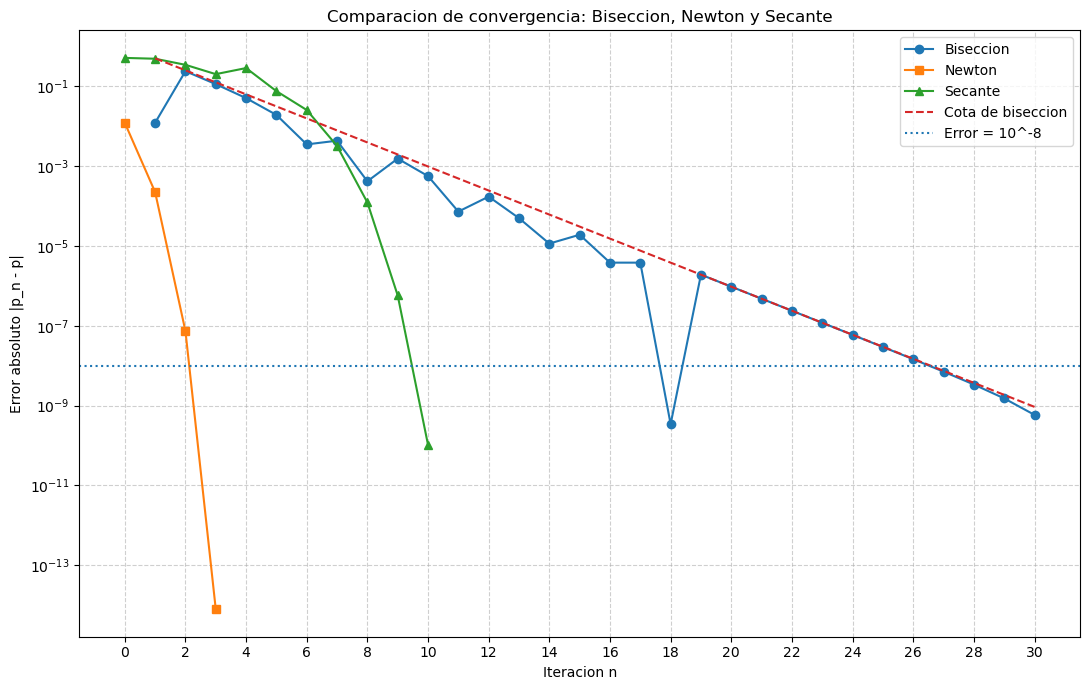

In [9]:

import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return 3*x - np.exp(x)

def df(x):
    return 3 - np.exp(x)

# Metodo de la secante para calcular la raiz

def secante_raiz(p0, p1, TOL=1e-14, Nmax=100):
    for i in range(Nmax):
        if f(p1) == f(p0):
            break

        p = p1 - f(p1)*(p1-p0)/(f(p1)-f(p0))

        if abs(p-p1) < TOL:
            return p

        p0, p1 = p1, p

    return p1

raiz = secante_raiz(1.0, 2.0)

print("Raiz de referencia:", format(raiz, ".16f"))


# Metodo de biseccion (30 iteraciones)
def biseccion(a, b, N=30):
    historia = []

    for i in range(N):
        p = (a+b)/2
        historia.append(p)

        if f(a)*f(p) < 0:
            b = p
        else:
            a = p

    return historia

hist_bis = biseccion(1, 2, 30)


# Metodo de Newton
def newton(p0, TOL=1e-14, Nmax=30):
    historia = [p0]

    for i in range(Nmax):
        if df(p0) == 0:
            break

        p = p0 - f(p0)/df(p0)
        historia.append(p)

        if abs(p-p0) < TOL:
            break

        p0 = p
    return historia
hist_newton = newton(1.5)


#  Metodo de la secante

def secante(p0, p1, TOL=1e-14, Nmax=30):
    historia = [p0, p1]

    for i in range(Nmax):
        if f(p1) == f(p0):
            break

        p = p1 - f(p1)*(p1-p0)/(f(p1)-f(p0))
        historia.append(p)

        if abs(p-p1) < TOL:
            break

        p0, p1 = p1, p

    return historia
hist_secante = secante(1.0, 2.0)

#  Calcular los errores absolutos
errores_bis = [abs(pn-raiz) for pn in hist_bis]
errores_newton = [abs(pn-raiz) for pn in hist_newton]
errores_secante = [abs(pn-raiz) for pn in hist_secante]


# Preparar los datos para la grafica

n_bis = np.arange(1, len(hist_bis)+1)
n_newton = np.arange(len(hist_newton))
n_secante = np.arange(len(hist_secante))
cota_bis = (2-1)/(2.0**n_bis)

def filtrar_ceros(n, errores):
    n_filtrado = []
    errores_filtrados = []

    for ni, error in zip(n, errores):
        if error > 0:
            n_filtrado.append(ni)
            errores_filtrados.append(error)

    return n_filtrado, errores_filtrados


n_newton_f, errores_newton_f = filtrar_ceros(
    n_newton, errores_newton
)

n_secante_f, errores_secante_f = filtrar_ceros(
    n_secante, errores_secante
)


# Grafica de convergencia

plt.figure(figsize=(11, 7))
plt.semilogy(
    n_bis, errores_bis,
    'o-', label='Biseccion'
)

plt.semilogy(
    n_newton_f, errores_newton_f,
    's-', label='Newton'
)

plt.semilogy(
    n_secante_f, errores_secante_f,
    '^-', label='Secante'
)

plt.semilogy(
    n_bis, cota_bis,
    '--', label='Cota de biseccion'
)

plt.axhline(
    y=1e-8,
    linestyle=':',
    label='Error = 10^-8'
)

plt.xlabel('Iteracion n')
plt.ylabel('Error absoluto |p_n - p|')
plt.title('Comparacion de convergencia: Biseccion, Newton y Secante')

plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.legend()
plt.xticks(np.arange(0, 31, 2))
plt.savefig("convergencia_metodos.png", dpi=150)
plt.tight_layout()
plt.show()


In [8]:

print("\nNumero de aproximaciones:")
print("Biseccion:", len(hist_bis))
print("Newton:", len(hist_newton))
print("Secante:", len(hist_secante))

print("\nErrores finales:")
print("Biseccion:", errores_bis[-1])
print("Newton:", errores_newton[-1])
print("Secante:", errores_secante[-1])



Numero de aproximaciones:
Biseccion: 30
Newton: 5
Secante: 13

Errores finales:
Biseccion: 5.872118347127753e-10
Newton: 0.0
Secante: 0.0
